# 3D-10 — SIG web : couches, repères et niveaux de détail

[← Photogrammétrie et MNT (3D-09)](3D-09-Photogrammetrie-MNT-Python.ipynb) | [→ Qualifier un MNT (3D-11)](3D-11-Qualifier-un-MNT-SIG-Python.ipynb) | [← Série GenAI/3D](README.md)

Ce carnet construit un mini-système cartographique reproductible à partir de données synthétiques : une grille d'altitudes, des emprises et une vue matricielle. Il sert à distinguer trois familles de services qui ne sont pas interchangeables : **WMS** rend une carte en image ; **WMTS** sert des images pré-tuilées à plusieurs échelles ; un service de **terrain** fournit une surface altimétrique ; **3D Tiles** diffuse des contenus 3D hiérarchisés, par exemple des bâtiments ou un maillage. Une orthophoto n'est pas un MNT, et des tuiles 3D ne garantissent pas une précision géométrique.

Le but est d'enseigner les couches, échelles, transformations de coordonnées, profils de terrain et compromis de diffusion. Aucun service distant, jeton, jeu privé, ni dépendance Cesium n'est requis pour exécuter les cellules. L'aperçu final optionnel est du HTML générique, pas un client Cesium et ne prétend pas démontrer le chargement de 3D Tiles.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

GRAINE = 2026
rng = np.random.default_rng(GRAINE)
print(f"NumPy {np.__version__} — graine fixée : {GRAINE}")

NumPy 2.4.2 — graine fixée : 2026


## 1. Construire les couches cartographiques

On utilise un repère local projeté synthétique en mètres. Les bâtiments sont des vecteurs (polygones) ; le terrain est une grille raster ; l'orthophoto est simulée comme image RGB. Cette juxtaposition rappelle que chaque couche a une géométrie, une résolution et une sémantique propres.

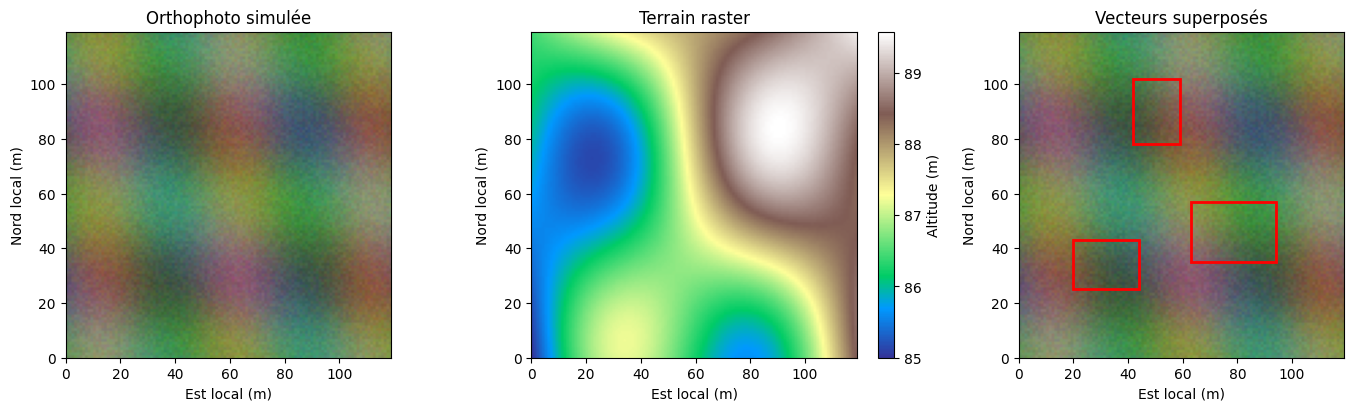

Raster : (120, 120), pas nominal 1.0 m ; bâtiments : 3


In [2]:
n = 120
x = np.linspace(0, 119, n)
y = np.linspace(0, 119, n)
X, Y = np.meshgrid(x, y)
terrain = 85 + 0.025 * X + 0.012 * Y + 1.4 * np.sin(X / 18) * np.cos(Y / 25)
# Trois emprises rectangulaires, repérées dans le même repère local.
batiments = [(20, 25, 24, 18, 7), (63, 35, 31, 22, 11), (42, 78, 17, 24, 6)]
ortho = np.stack([
    np.clip(0.35 + 0.15*np.sin(X/8) + 0.08*rng.random((n,n)), 0, 1),
    np.clip(0.42 + 0.12*np.cos(Y/9) + 0.08*rng.random((n,n)), 0, 1),
    np.clip(0.30 + 0.10*np.sin((X+Y)/12) + 0.08*rng.random((n,n)), 0, 1)
], axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
axes[0].imshow(ortho, origin="lower", extent=[0,119,0,119]); axes[0].set_title("Orthophoto simulée")
im = axes[1].imshow(terrain, origin="lower", extent=[0,119,0,119], cmap="terrain"); fig.colorbar(im, ax=axes[1], label="Altitude (m)" ); axes[1].set_title("Terrain raster")
axes[2].imshow(ortho, origin="lower", extent=[0,119,0,119])
for bx, by, w, h, _ in batiments:
    axes[2].add_patch(plt.Rectangle((bx,by),w,h,fill=False,edgecolor="red",linewidth=2))
axes[2].set_title("Vecteurs superposés")
for ax in axes: ax.set_xlabel("Est local (m)"); ax.set_ylabel("Nord local (m)")
plt.show()
print(f"Raster : {terrain.shape}, pas nominal {x[1]-x[0]:.1f} m ; bâtiments : {len(batiments)}")

### Lecture du résultat

L'orthophoto et le raster ont le même emprise dans ce jouet, mais ils n'ont pas la même information : l'une est une image de couleurs, l'autre porte une altitude par cellule. Les rectangles sont des entités vectorielles séparées. Les superposer exige un CRS et une transformation compatibles ; ici le partage du repère est construit par le code, pas acquis à partir de métadonnées.

## 2. Interroger le raster et extraire un profil

Une requête d'altitude est valide seulement si le point est transformé dans le CRS du raster et tombe dans son emprise. Le profil ci-dessous est calculé le long d'une ligne de la grille synthétique ; il illustre une opération SIG simple sans convertir les coordonnées ni charger de données externes.

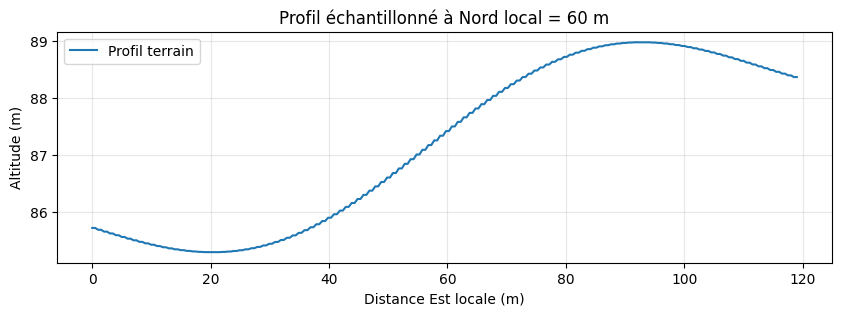

Contrôle hors emprise : Point hors emprise du raster


In [3]:
def interroger_altitude(x_m, y_m, raster, x_coords=x, y_coords=y):
    """Échantillonne au pixel le plus proche dans le repère local de démonstration."""
    if not (x_coords.min() <= x_m <= x_coords.max() and y_coords.min() <= y_m <= y_coords.max()):
        raise ValueError("Point hors emprise du raster")
    col = int(np.argmin(np.abs(x_coords - x_m)))
    row = int(np.argmin(np.abs(y_coords - y_m)))
    return float(raster[row, col])

ligne_y = 60.0
profil_x = np.linspace(0, 119, 240)
profil_z = np.array([interroger_altitude(px, ligne_y, terrain) for px in profil_x])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(profil_x, profil_z, label="Profil terrain")
for bx, by, w, h, hauteur in batiments:
    if by <= ligne_y <= by+h:
        ax.axvspan(bx, bx+w, color="tab:orange", alpha=0.2, label="Emprise bâtiment")
ax.set(xlabel="Distance Est locale (m)", ylabel="Altitude (m)", title="Profil échantillonné à Nord local = 60 m")
ax.grid(True, alpha=0.3); ax.legend(); plt.show()
try:
    interroger_altitude(130, 60, terrain)
except ValueError as exc:
    print(f"Contrôle hors emprise : {exc}")

## 3. Niveaux de détail : l'idée, puis la limite

Pour rendre le compromis mesurable sans inventer de tuiles 3D, on compare un maillage raster monolithique à des grilles sous-échantillonnées. Les niveaux grossiers contiennent moins de sommets et sont moins coûteux à transmettre, mais ils perdent les détails. Un système hiérarchique réel choisit les tuiles selon la caméra, l'erreur d'écran, la disponibilité réseau et la mémoire. Ici, on estime uniquement le nombre de sommets des grilles ; **ce n'est pas un format 3D Tiles ni une mesure réseau**.

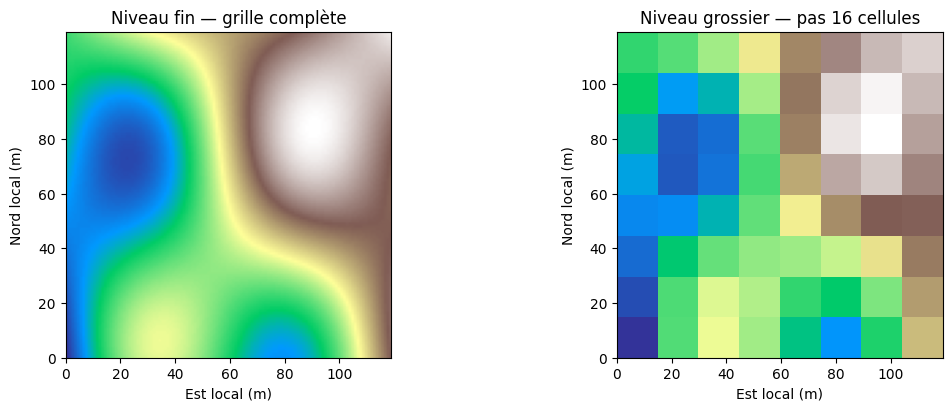

Pas | dimensions | sommets | fraction de la grille complète
  1 | 120 × 120 |  14400 | 100.0%
  2 | 60 × 60 |   3600 | 25.0%
  4 | 30 × 30 |    900 | 6.2%
  8 | 15 × 15 |    225 | 1.6%
 16 | 8 × 8 |     64 | 0.4%


In [4]:
# Échantillonner une grille régulière à plusieurs pas ; le pas 1 conserve tous les points.
pas_lod = [1, 2, 4, 8, 16]
# Le slicing réduit les deux axes : chaque grille représente le même secteur, moins dense.
maillages = [terrain[::p, ::p] for p in pas_lod]
# Cette comparaison porte sur le nombre de sommets, pas sur le volume réseau réel.
nb_sommets = np.array([m.size for m in maillages])
charge_relative = nb_sommets / nb_sommets[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
# Garder la même emprise évite de confondre réduction de résolution et zoom.
axes[0].imshow(terrain, origin="lower", extent=[0,119,0,119], cmap="terrain")
axes[0].set_title("Niveau fin — grille complète")
axes[1].imshow(maillages[-1], origin="lower", extent=[0,119,0,119], cmap="terrain", interpolation="nearest")
axes[1].set_title(f"Niveau grossier — pas {pas_lod[-1]} cellules")
for ax in axes: ax.set_xlabel("Est local (m)"); ax.set_ylabel("Nord local (m)")
plt.show()
print("Pas | dimensions | sommets | fraction de la grille complète")
for pas, grille, nb, fraction in zip(pas_lod, maillages, nb_sommets, charge_relative):
    print(f"{pas:>3} | {grille.shape[1]} × {grille.shape[0]} | {nb:>6} | {fraction:.1%}")

### Lecture du résultat

Le sous-échantillonnage réduit fortement le nombre de sommets, mais les petites formes disparaissent ou changent de contour. Pour un chargement progressif, il faut une hiérarchie spatiale et une règle de raffinement : une seule grille grossière choisie pour tout l'écran ferait perdre le détail même là où il est visible. Des niveaux LOD ne récupèrent pas les objets absents des images d'origine et ne certifient pas l'exactitude du terrain.

## 4. Capturer la preuve d'un raffinement visuel

Dans une application web, comparer deux captures à caméra et viewport constants : (a) première image après ouverture ; (b) image stabilisée après téléchargement et raffinement. Relever l'heure des captures, le niveau de zoom, les ressources réseau chargées, la mémoire et les erreurs. Refaire la vue depuis un second angle pour distinguer une texture bien projetée d'une géométrie plausible. Le code local ci-dessous fabrique deux rendus à résolutions différentes pour illustrer ce protocole ; ce n'est pas une capture d'un viewer ni une preuve de chargement progressif.

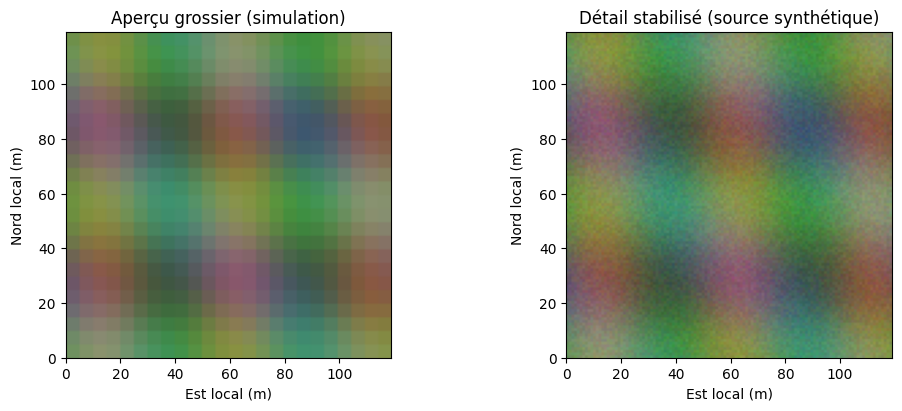

Image synthétique : 120 × 120 pixels ; aperçu simulé : 24 × 24 pixels.
Aucune mesure de latence, requête HTTP ou qualité 3D n'est effectuée ici.


In [5]:
# Démonstration d'image basse définition vs détail stabilisé, issue de la même orthophoto synthétique.
from PIL import Image
image = Image.fromarray((ortho * 255).astype(np.uint8))
# Réduire puis agrandir illustre une apparence grossière, sans simuler un chargement réseau réel.
aperçu_initial = image.resize((24, 24), resample=Image.Resampling.BILINEAR).resize((n, n), resample=Image.Resampling.NEAREST)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].imshow(aperçu_initial, origin="lower", extent=[0,119,0,119]); axes[0].set_title("Aperçu grossier (simulation)")
axes[1].imshow(ortho, origin="lower", extent=[0,119,0,119]); axes[1].set_title("Détail stabilisé (source synthétique)")
# Même emprise et cadrage : seule la résolution de l'image affichée varie.
for ax in axes: ax.set_xlabel("Est local (m)"); ax.set_ylabel("Nord local (m)")
plt.show()
print(f"Image synthétique : {image.size[0]} × {image.size[1]} pixels ; aperçu simulé : 24 × 24 pixels.")
print("Aucune mesure de latence, requête HTTP ou qualité 3D n'est effectuée ici.")

## 5. Choisir un service selon la donnée

| Besoin | Produit adapté | Ce qu'il ne fournit pas à lui seul |
|---|---|---|
| Carte raster affichée rapidement | WMS | accès aux pixels bruts ou géométrie 3D |
| Images cartographiques pré-tuilées | WMTS | terrain altimétrique ou bâtiments 3D |
| Surface de terrain interrogeable | service de terrain / raster d'altitude | orthophoto ou modèles de bâtiments |
| Maillages/bâtiments détaillés hiérarchisés | 3D Tiles | vérité terrain, précision certifiée ou sémantique SIG automatique |
| Données à analyser localement | GeoTIFF, GeoPackage, LAS/LAZ selon besoin | rendu web progressif sans service dédié |

Le protocole du projet doit vérifier les métadonnées de chaque couche, l'unité, le CRS et le datum vertical. Un fond d'imagerie en coordonnées géographiques et un raster métrique ne se superposent correctement qu'après transformation explicite.

## 6. Exercices et vérifications

1. Modifier la taille de l'aperçu et tracer le compromis entre nombre de pixels et perte de détail ; ne pas appeler cela une précision métrique.
2. Ajouter un point de contrôle, vérifier son emprise et extraire l'altitude. Expliquer pourquoi des coordonnées longitude/latitude ne peuvent pas être passées directement à cette fonction qui attend des mètres locaux.
3. Pour un vrai viewer, proposer une mesure reproductible du temps initial, du délai jusqu'à la stabilisation et du nombre de ressources supplémentaires après zoom. Nommer deux angles de vue et trois détails témoins de vos propres images.
4. Associer WMS, WMTS, terrain et 3D Tiles aux bonnes couches d'un scénario. Identifier ce qui doit être mesuré séparément pour certifier le MNT.

Ces exercices ne nécessitent ni clé, ni serveur distant ; ils ne fabriquent pas de données de service.

In [6]:
def choisir_service(besoin):
    """TODO étudiant : associer un besoin parmi image, terrain, maillage aux services."""
    return None

besoin_test = "terrain"
service = choisir_service(besoin_test)
if service is None:
    print("Exercice à compléter")
else:
    assert service in {"GeoTIFF", "service de terrain"}
    print("Exercice réussi")

Exercice à compléter


## À retenir

- WMS/WMTS servent des cartes en image ; un terrain porte des altitudes ; 3D Tiles diffuse des objets 3D par niveaux de détail. Ces produits ne se remplacent pas.
- Une image plus nette et un maillage plus dense ne prouvent pas un MNT plus exact.
- La comparaison avant/après doit tenir le secteur, le viewport et la caméra fixes, puis inclure un second angle et des détails témoins visibles dans les photos.
- Le sous-échantillonnage utilisé ici n'est pas un tuilage 3D Tiles. Ce carnet ne démontre ni un serveur Cesium, ni des performances réseau.
- Avant toute conclusion de précision, documenter les CRS, les unités, le datum vertical, les points de contrôle indépendants et les limites de la reconstruction.

[← Carnet précédent : photogrammétrie et MNT (3D-09)](3D-09-Photogrammetrie-MNT-Python.ipynb)